In [70]:

import random

# Eight possible movement directions
DIRS = [
    (-1, 0), (1, 0),
    (0, -1), (0, 1),
    (-1, -1), (-1, 1),
    (1, -1), (1, 1)
]

class Courtyard:
    def __init__(self, n=100, size=30, p=0.15, seed=0):
        self.rng = random.Random(seed)

        self.n = n
        self.size = size
        self.p = p
        self.tick = 0

        # Random positions of students
        self.pos = [
            (self.rng.randrange(size), self.rng.randrange(size))
            for _ in range(n)
        ]

        # Initially nobody knows the rumour
        self.knows = [False] * n

        # Student 0 knows the rumour
        self.knows[0] = True

    def count(self):
        return sum(self.knows)


    def render(self):
        rows = [["_"] * self.size for _ in range(self.size)]

        for i, (r, c) in enumerate(self.pos):
            if self.knows[i]:
                rows[r][c] = "R"
            elif rows[r][c] == "_":
                rows[r][c] = "E"

        return "\n".join("".join(row) for row in rows)



# Create courtyard
courtyard = Courtyard(n=12, size=10, seed=1)

print(courtyard.render())
print("Students who know the rumour:", courtyard.count())


______EE__
____E__E__
_________R
__________
___E______
E_________
___E_____E
_______E__
__________
_E________
Students who know the rumour: 1


In [71]:

# Activity 2: Add rules to our existing Courtyard

class Courtyard(Courtyard):

    # Rule 1: Move students randomly
    def move_all(self):
        for i in range(self.n):
            dr, dc = self.rng.choice(DIRS)
            r, c = self.pos[i]

            self.pos[i] = (
                (r + dr) % self.size,
                (c + dc) % self.size
            )

    # Rule 2: Check nearby students
    def next_to_knower(self, cell, know_cells):
        r, c = cell

        return any(
            ((r + a) % self.size,
             (c + b) % self.size) in know_cells
            for a in (-1, 0, 1)
            for b in (-1, 0, 1)
        )

    # Rule 3: Spread the rumour
    def spread(self):
        know_cells = {
            self.pos[i]
            for i in range(self.n)
            if self.knows[i]
        }

        newly = [
            i for i in range(self.n)
            if not self.knows[i]
            and self.next_to_knower(self.pos[i], know_cells)
            and self.rng.random() < self.p
        ]

        for i in newly:
            self.knows[i] = True

    # Rule 4: Run one tick
    def step(self):
        self.move_all()
        self.spread()
        self.tick += 1


print("Activity 2: Rules added successfully!")


Activity 2: Rules added successfully!


In [72]:

# Create a new courtyard
courtyard = Courtyard(n=12, size=10, p=0.3, seed=1)

print("BEFORE MOVEMENT:")
print(courtyard.render())
print("Students who know:", courtyard.count())

# Execute one tick
courtyard.step()

print("\nAFTER ONE TICK:")
print(courtyard.render())
print("Students who know:", courtyard.count())
print("Current tick:", courtyard.tick)


BEFORE MOVEMENT:
______EE__
____E__E__
_________R
__________
___E______
E_________
___E_____E
_______E__
__________
_E________
Students who know: 1

AFTER ONE TICK:
____E__E__
________RR
______E___
__________
_E________
____E_____
E___E_____
__________
______E___
__E___E___
Students who know: 2
Current tick: 1


In [73]:

courtyard = Courtyard(n=12, size=10, p=0.3, seed=1)

for t in range(10):
    courtyard.step()

    print(f"Tick {courtyard.tick}")
    print(courtyard.render())
    print("Rumour knowing students:", courtyard.count())
    print("-" * 30)


Tick 1
____E__E__
________RR
______E___
__________
_E________
____E_____
E___E_____
__________
______E___
__E___E___
Rumour knowing students: 2
------------------------------
Tick 2
_E________
R____E____
________R_
______E___
__E__E____
_________E
__________
___E__E___
__________
_____EE___
Rumour knowing students: 2
------------------------------
Tick 3
____E_____
_E_______R
_R__E_____
______E___
_____E____
___E____E_
__________
____E_____
______EE__
__________
Rumour knowing students: 2
------------------------------
Tick 4
________R_
E____E____
___E______
_R___E____
_____E__E_
__E_______
__________
________E_
_____E____
_____E____
Rumour knowing students: 2
------------------------------
Tick 5
______E___
___E______
______E__E
__R__E____
__________
_E_______E
__________
_________E
__________
____E_ER__
Rumour knowing students: 2
------------------------------
Tick 6
___E__RE__
_______R_E
______E___
_____E____
RRE_______
__________
E_________
__________
__________
_____R____
Rumour k

In [74]:

# Activity 3: Run and Log the Tick Loop

def run_rumour(model, max_ticks=550, every=15):

    print("Tick | Students Who Know")
    print("------------------------")
    print(f"{model.tick:4d} | {model.count():3d}")

    # Continue until everyone knows or max ticks reached
    while model.count() < model.n and model.tick < max_ticks:

        model.step()

        # Record after every 10 ticks
        if model.tick % every == 0:
            print(f"{model.tick:4d} | {model.count():3d}")

    # Final result
    if model.count() == model.n:
        print(f"\nEveryone knows after {model.tick} ticks!")
    else:
        print(f"\nStopped at tick {model.tick} with {model.count()} knowers")


# Create full-size courtyard and run simulation
courtyard = Courtyard(n=100, size=30, p=15, seed=3)

run_rumour(courtyard)


Tick | Students Who Know
------------------------
   0 |   1
  15 |  43
  30 |  90
  45 | 100

Everyone knows after 45 ticks!


In [75]:

# Task 1: Many Runs, Not One

import statistics

# Find ticks required to reach a target fraction
def ticks_until(model, fraction, max_ticks=450):

    target = fraction * model.n

    while model.count() < target and model.tick < max_ticks:
        model.step()

    return model.tick


# Calculate average ticks over multiple seeds
def average_ticks(p, fraction, seeds=range(30), **kwargs):

    return statistics.mean(
        ticks_until(
            Courtyard(p=p, seed=s, **kwargs),
            fraction
        )
        for s in seeds
    )


# Average time to reach 65% students
half = average_ticks(0.3, 0.65)

# Average time to reach 35% students
ninety = average_ticks(0.3, 0.35)

print("Half know after", round(half, 1), "ticks on average")
print("90 percent know after", round(ninety, 1), "ticks on average")


# Find fastest and slowest runs
runs = [
    ticks_until(Courtyard(p=0.3, seed=s), 0.9)
    for s in range(30)
]

print("Single runs to 65 percent:")
print("Fastest:", min(runs))
print("Slowest:", max(runs))


Half know after 50.8 ticks on average
90 percent know after 36.8 ticks on average
Single runs to 65 percent:
Fastest: 50
Slowest: 87


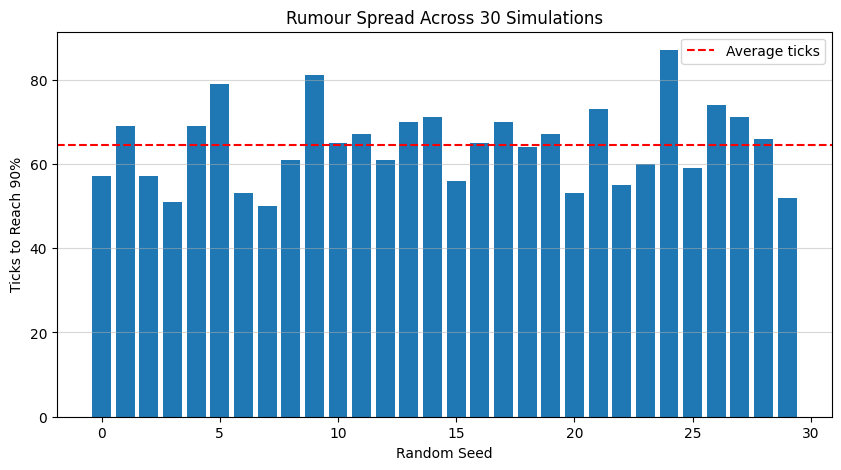

In [79]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(range(30), runs)
plt.axhline(
    y=statistics.mean(runs),
    color="red",
    linestyle="--",
    label="Average ticks"
)

plt.xlabel("Random Seed")
plt.ylabel("Ticks to Reach 90%")
plt.title("Rumour Spread Across 30 Simulations")
plt.legend()
plt.grid(axis="y", alpha=0.5)
plt.show()


In [81]:

# Task 2: Change the Rumour Spreading Probability

for p in [0.15, 0.35, 0.55, 0.8]:

    # Average ticks until 50% students know
    half = average_ticks(p, 0.5)

    # Average ticks until 90% students know
    ninety = average_ticks(p, 0.9)

    # Print the results
    print(f"p = {p}: half {half:.1f}, 90% {ninety:.1f}")


p = 0.15: half 65.4, 90% 94.5
p = 0.35: half 41.5, 90% 60.2
p = 0.55: half 34.8, 90% 49.6
p = 0.8: half 28.8, 90% 43.0


In [82]:

# Task 2: Change the Rumour Spreading Probability

for p in [0.1, 0.3, 0.6, 1.0]:

    # Average ticks until 50% students know
    half = average_ticks(p, 0.5)

    # Average ticks until 90% students know
    ninety = average_ticks(p, 0.9)

    # Print the results
    print(f"p = {p}: half {half:.1f}, 90% {ninety:.1f}")


p = 0.1: half 81.4, 90% 120.7
p = 0.3: half 43.8, 90% 64.4
p = 0.6: half 34.2, 90% 50.5
p = 1.0: half 26.5, 90% 39.6


In [83]:

# Task 3: Some Students Stay Home

class CourtyardStayHome(Courtyard):

    def __init__(self, stay_home=0.0, **kwargs):
        super().__init__(**kwargs)

        # Number of students who stay home
        k = round(stay_home * self.n)

        # Last k students will stay home
        self.frozen = set(range(self.n - k, self.n))

    # Override the movement rule
    def move_all(self):

        for i in range(self.n):

            # Skip students who stay home
            if i in self.frozen:
                continue

            # Other students move normally
            dr, dc = self.rng.choice(DIRS)
            r, c = self.pos[i]

            self.pos[i] = (
                (r + dr) % self.size,
                (c + dc) % self.size
            )


print("Task 3: Stay-home rule added successfully!")


Task 3: Stay-home rule added successfully!


In [84]:

# Test stationary students

model = CourtyardStayHome(
    n=10,
    size=10,
    p=0.3,
    seed=1,
    stay_home=0.3
)

print("Frozen student IDs:", model.frozen)

before = model.pos.copy()

model.step()

after = model.pos.copy()

for i in range(model.n):
    status = "STAY HOME" if i in model.frozen else "MOVING"

    print(
        f"Student {i}: {before[i]} -> {after[i]} | {status}"
    )


Frozen student IDs: {8, 9, 7}
Student 0: (2, 9) -> (3, 9) | MOVING
Student 1: (1, 4) -> (0, 5) | MOVING
Student 2: (1, 7) -> (0, 7) | MOVING
Student 3: (7, 7) -> (6, 7) | MOVING
Student 4: (6, 3) -> (5, 3) | MOVING
Student 5: (1, 7) -> (0, 7) | MOVING
Student 6: (0, 6) -> (1, 5) | MOVING
Student 7: (6, 9) -> (6, 9) | STAY HOME
Student 8: (0, 7) -> (0, 7) | STAY HOME
Student 9: (4, 3) -> (4, 3) | STAY HOME
